In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

Data Cleaning

In [2]:
df = pd.read_csv("nykaa_campaign_data.csv")
df.head()

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,111.03,6.14,Hindi,20.98,College Students,29-04-2025
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,180.83,3.26,Hindi,7.24,College Students,06-04-2025
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,90.60,1.88,English,25.03,College Students,14-01-2025
3,NY-CMP-1003,Email,Working Women,18,"YouTube, Facebook, Instagram",88114,8413,2231,947,376906,249.07,0.60,Hindi,13.15,College Students,04-06-2025
4,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55555 entries, 0 to 55554
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Campaign_ID       55555 non-null  str    
 1   Campaign_Type     55555 non-null  str    
 2   Target_Audience   55555 non-null  str    
 3   Duration          55555 non-null  int64  
 4   Channel_Used      55555 non-null  str    
 5   Impressions       55555 non-null  int64  
 6   Clicks            55555 non-null  int64  
 7   Leads             55555 non-null  int64  
 8   Conversions       55555 non-null  int64  
 9   Revenue           55555 non-null  int64  
 10  Acquisition_Cost  55555 non-null  float64
 11  ROI               55555 non-null  float64
 12  Language          55555 non-null  str    
 13  Engagement_Score  55555 non-null  float64
 14  Customer_Segment  55555 non-null  str    
 15  Date              55555 non-null  str    
dtypes: float64(3), int64(6), str(7)
memory usage: 11.0 

In [4]:
df.isnull().sum()

Campaign_ID         0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Impressions         0
Clicks              0
Leads               0
Conversions         0
Revenue             0
Acquisition_Cost    0
ROI                 0
Language            0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score
count,55555.000000,55555.000000,55555.000000,55555.000000,55555.000000,5.555500e+04,55555.000000,55555.000000,55555.000000
mean,17.446044,55087.885357,4688.070507,1877.271119,1032.866925,5.158197e+05,377.347068,2.713807,13.784169
std,7.520438,25930.001514,3178.686285,1435.636117,862.496788,4.900121e+05,541.084524,4.493380,6.353125
min,5.000000,10001.000000,202.000000,56.000000,19.000000,6.183000e+03,9.080000,-0.970000,2.600000
25%,11.000000,32680.000000,2110.000000,779.000000,400.000000,1.777060e+05,105.435000,0.040000,8.360000
50%,17.000000,55182.000000,3907.000000,1481.000000,779.000000,3.604360e+05,207.510000,1.240000,13.600000
75%,24.000000,77514.500000,6688.000000,2605.000000,1414.000000,6.874225e+05,428.580000,3.630000,18.855000
max,30.000000,100000.000000,14868.000000,8876.000000,6686.000000,4.579910e+06,15473.160000,74.420000,30.910000


In [7]:
df['Date'] = pd.to_datetime(df['Date'] , format='%d-%m-%Y')

In [8]:
df['Number_of_Channels'] = df['Channel_Used'].str.split(',').str.len()

In [9]:
df['Channel_Used'].str.split(', ').explode().unique()

<ArrowStringArray>
['WhatsApp', 'YouTube', 'Google', 'Facebook', 'Instagram', 'Email']
Length: 6, dtype: str

In [10]:
df['WhatsApp'] = df['Channel_Used'].str.contains('WhatsApp').astype(int)

df['YouTube'] = df['Channel_Used'].str.contains('YouTube').astype(int)

df['Google'] = df['Channel_Used'].str.contains('Google').astype(int)

df['Facebook'] = df['Channel_Used'].str.contains('Facebook').astype(int)

df['Instagram'] = df['Channel_Used'].str.contains('Instagram').astype(int)

df['Email'] = df['Channel_Used'].str.contains('Email').astype(int)

In [11]:
df['Spend'] = df['Acquisition_Cost']*df['Conversions']

In [12]:
df['CTR'] = (df['Clicks']/df['Impressions'])*100

In [13]:
df['Lead_Rate'] = (df['Leads']/df['Clicks'])*100

In [14]:
df['Lead_to_Conversion_Rate'] = (df['Conversions']/df['Leads'])*100

In [15]:
df['Conversion_Rate'] = (df['Conversions']/df['Impressions'])*100

In [16]:
df.head()

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,...,YouTube,Google,Facebook,Instagram,Email,Spend,CTR,Lead_Rate,Lead_to_Conversion_Rate,Conversion_Rate
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,...,1,0,0,0,0,261475.65,10.649782,58.739441,65.127212,4.074113
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,...,1,0,0,0,0,245386.31,3.617608,59.349593,68.848300,1.478197
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,...,1,1,0,0,0,68403.00,14.044799,43.629698,79.306723,4.859681
3,NY-CMP-1003,Email,Working Women,18,"YouTube, Facebook, Instagram",88114,8413,2231,947,376906,...,1,0,1,1,0,235869.29,9.547858,26.518483,42.447333,1.074744
4,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296,...,0,0,1,1,0,287578.80,3.863901,55.036067,61.067961,1.298634


Exploratory Data Analysis

Which campaigns and campaign types generate the highest ROI?

In [17]:
#Campaign Type Distribution
df['Campaign_Type'].value_counts()

Campaign_Type
Influencer      11134
Paid Ads        11116
Social Media    11114
Email           11112
SEO             11079
Name: count, dtype: int64

In [18]:
#ROI and Conversion Rate per Campaign Type 
campaign_type_performance = df.groupby('Campaign_Type')[['ROI', 'Conversion_Rate']].mean().reset_index().sort_values(by = 'ROI', ascending = False)
campaign_type_performance

,Campaign_Type,ROI,Conversion_Rate
4,Social Media,2.754784,1.883148
2,Paid Ads,2.722275,1.857936
3,SEO,2.709630,1.864965
1,Influencer,2.699687,1.881697
0,Email,2.682663,1.874902


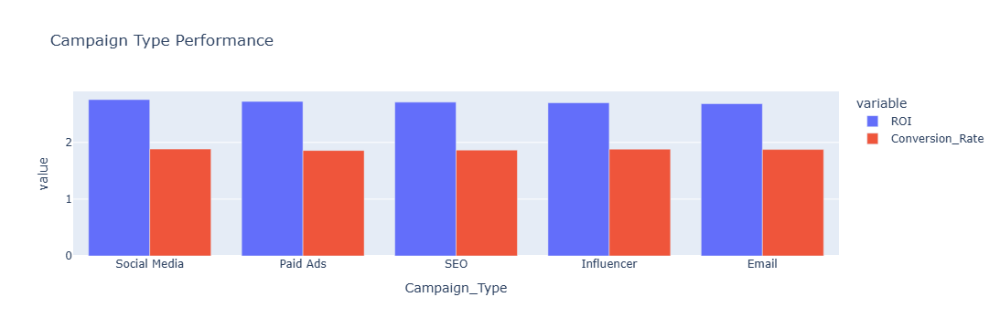

In [19]:
fig = px.bar(
    campaign_type_performance,
    x = 'Campaign_Type',
    y = ['ROI', 'Conversion_Rate'],
    barmode = 'group',
    title = 'Campaign Type Performance')
fig.show()

In [20]:
#Revenue and Spend per Campaign Type
campaign_type_spend = df.groupby('Campaign_Type')[['Revenue', 'Spend']].mean().reset_index().sort_values(by = 'Revenue', ascending = False)
print(campaign_type_spend)

  Campaign_Type        Revenue          Spend
1    Influencer  518148.378301  175682.520728
4  Social Media  517530.827785  174126.828013
2      Paid Ads  517404.550468  174896.059031
3           SEO  514381.428559  173732.925463
0         Email  511623.631030  174486.900381


In [21]:
df.nlargest(10, 'ROI')[
    ['Campaign_ID', 'Campaign_Type', 'ROI', 'Target_Audience', 'Duration', 'Channel_Used', 'Revenue', 'Spend', 'Conversions','Conversion_Rate', 'Engagement_Score']]

,Campaign_ID,Campaign_Type,ROI,Target_Audience,Duration,Channel_Used,Revenue,Spend,Conversions,Conversion_Rate,Engagement_Score
12007,NY-CMP-13007,Paid Ads,74.42,Youth,29,"Email, YouTube, Facebook",4579910,60708.88,6686,6.720746,30.17
21689,NY-CMP-22689,Influencer,66.32,Youth,20,"Instagram, YouTube",3821485,56764.20,5315,5.463554,27.26
48715,NY-CMP-49715,Paid Ads,65.00,Premium Shoppers,12,WhatsApp,3717208,56341.12,4664,5.215369,25.54
25356,NY-CMP-26356,Paid Ads,64.14,Premium Shoppers,5,Facebook,3363384,51641.76,4764,5.242077,27.06
38329,NY-CMP-39329,Paid Ads,59.64,Youth,27,"Google, Facebook, YouTube",3168256,52267.52,4352,5.609838,27.64
1174,NY-CMP-2174,Influencer,55.27,College Students,30,WhatsApp,3126600,55566.00,4050,4.174053,26.84
50204,NY-CMP-51204,Social Media,54.74,Premium Shoppers,24,"Google, Instagram, Email",2818458,50560.51,5051,5.155134,24.35
4736,NY-CMP-5736,Email,53.70,College Students,29,WhatsApp,3036187,55485.05,5633,5.904798,27.79
34197,NY-CMP-35197,Influencer,52.53,Premium Shoppers,25,Facebook,2796288,52248.35,3641,4.241563,20.71
23042,NY-CMP-24042,Social Media,52.45,Tier 2 City Customers,30,"Facebook, Google, WhatsApp",3146658,58860.51,4287,5.130814,26.03


In [22]:
df.nsmallest(10, 'ROI')[
    ['Campaign_ID', 'Campaign_Type', 'ROI', 'Target_Audience', 'Duration', 'Channel_Used', 'Revenue', 'Spend','Conversions', 'Conversion_Rate', 'Engagement_Score']]

,Campaign_ID,Campaign_Type,ROI,Target_Audience,Duration,Channel_Used,Revenue,Spend,Conversions,Conversion_Rate,Engagement_Score
8361,NY-CMP-9361,Social Media,-0.97,Tier 2 City Customers,12,"WhatsApp, Email",7584,229994.88,32,0.250313,2.82
23406,NY-CMP-24406,Paid Ads,-0.97,Premium Shoppers,5,"Facebook, YouTube",6183,183750.12,27,0.232258,3.32
10980,NY-CMP-11980,SEO,-0.96,Tier 2 City Customers,24,Google,12062,271759.08,37,0.160583,2.71
13988,NY-CMP-14988,Email,-0.96,Premium Shoppers,19,Instagram,8732,223014.91,37,0.341045,3.22
15583,NY-CMP-16583,Paid Ads,-0.96,Premium Shoppers,26,"Google, Instagram",8920,248473.00,20,0.163026,2.98
23680,NY-CMP-24680,Social Media,-0.96,College Students,8,YouTube,13005,293456.04,51,0.453333,4.86
35224,NY-CMP-36224,Social Media,-0.96,Working Women,27,"Google, Email",8800,239982.80,40,0.387072,6.85
40110,NY-CMP-41110,Email,-0.96,Youth,28,"Google, Email, YouTube",7945,209379.10,35,0.212160,3.49
52545,NY-CMP-53545,Paid Ads,-0.96,College Students,14,Facebook,9386,253684.96,38,0.344359,3.38
54748,NY-CMP-55748,Email,-0.96,Youth,16,YouTube,9972,238478.04,36,0.212477,3.22


Are we generating revenue efficiently, or simply spending more to get more conversions?

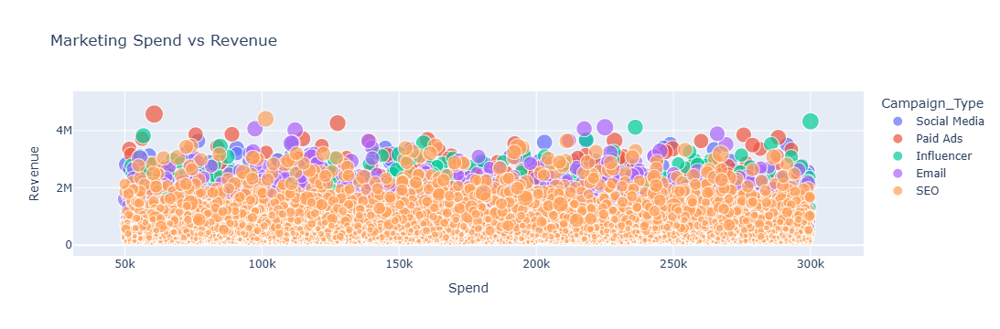

In [23]:
fig = px.scatter(
    df,
    x='Spend',
    y='Revenue',
    size='Conversions',
    color='Campaign_Type',
    hover_name='Campaign_ID',
    hover_data=['ROI', 'Conversion_Rate'],
    title='Marketing Spend vs Revenue'
)

fig.show()


Where is the biggest drop-off in the customer journey?

In [24]:
total_impressions = df['Impressions'].sum()
total_clicks = df['Clicks'].sum()
total_leads = df['Leads'].sum()
total_conversions = df['Conversions'].sum()

ctr = total_clicks / total_impressions * 100
lead_rate = total_leads / total_clicks * 100
conversion_rate = total_conversions / total_leads * 100

print("Impressions → Clicks:", ctr)
print("Clicks → Leads:", lead_rate)
print("Leads → Conversions:", conversion_rate)


Impressions → Clicks: 8.510166030763816
Clicks → Leads: 40.043576904959906
Leads → Conversions: 55.019592768163726


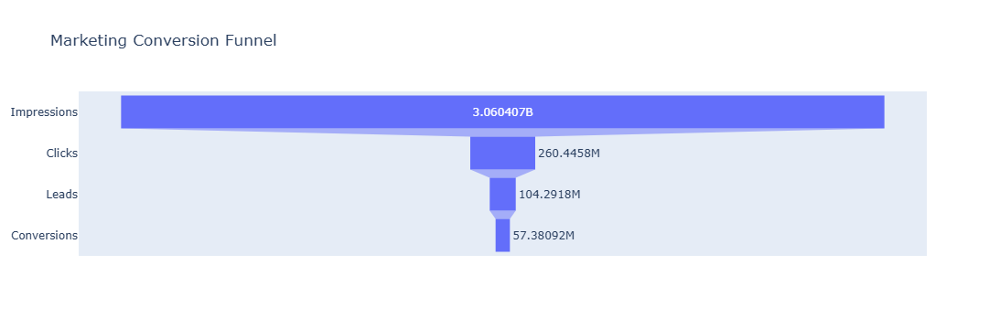

In [25]:
stages = ['Impressions', 'Clicks', 'Leads', 'Conversions']
values = [total_impressions, total_clicks,total_leads,total_conversions]

fig = go.Figure(go.Funnel(y = stages, x = values))

fig.update_layout(title = 'Marketing Conversion Funnel')
fig.show()

Which campaign types have the strongest/weakest funnel performance?

In [26]:
funnel_by_type = df.groupby('Campaign_Type').agg(
    CTR = ('CTR', 'mean'),
    Lead_Rate = ('Lead_Rate', 'mean'),
    Lead_to_Conversion_Rate = ('Lead_to_Conversion_Rate', 'mean')
).reset_index()

funnel_by_type

,Campaign_Type,CTR,Lead_Rate,Lead_to_Conversion_Rate
0,Email,8.474684,40.004828,55.181215
1,Influencer,8.560704,40.003233,55.018069
2,Paid Ads,8.513291,39.713542,54.910752
3,SEO,8.454946,40.041003,55.061524
4,Social Media,8.539556,39.931411,54.885066


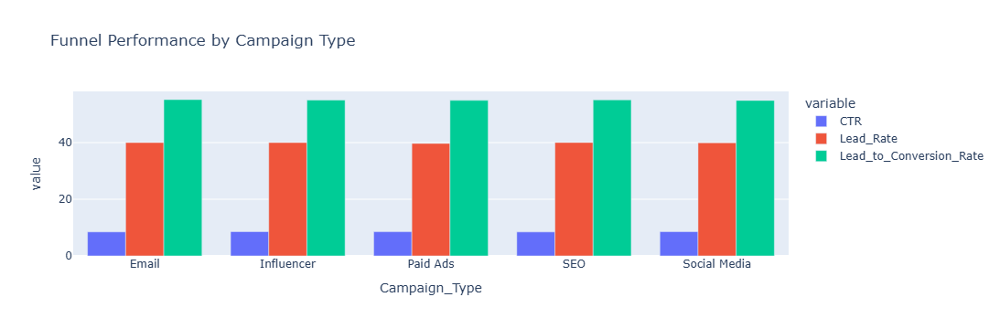

In [27]:
fig = px.bar(
    funnel_by_type,
    x = 'Campaign_Type',
    y = ['CTR', 'Lead_Rate', 'Lead_to_Conversion_Rate'],
    barmode = 'group',
    title = 'Funnel Performance by Campaign Type')
fig.show()

Does a higher CTR actually translate into more conversions?

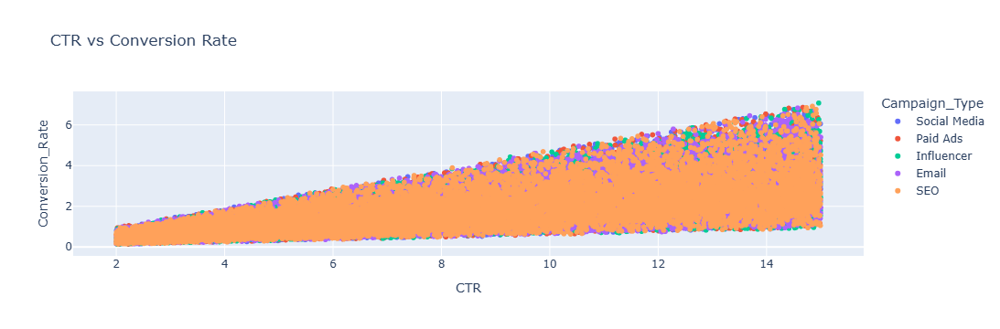

In [28]:
ctr_to_conversions = px.scatter(
    df, 
    x = 'CTR',
    y = 'Conversion_Rate',
    color = 'Campaign_Type',
    title = 'CTR vs Conversion Rate')

ctr_to_conversions.show()

In [29]:
df[['CTR', 'Conversion_Rate']].corr()

,CTR,Conversion_Rate
CTR,1.000000,0.713639
Conversion_Rate,0.713639,1.000000


Which customer segments are most valuable?

In [30]:
segment_performance = df.groupby('Customer_Segment')[['ROI', 'Conversion_Rate', 'Engagement_Score']].mean().reset_index().sort_values(by = 'ROI', ascending = False)
segment_performance

,Customer_Segment,ROI,Conversion_Rate,Engagement_Score
3,Working Women,2.771055,1.881642,13.873177
1,Premium Shoppers,2.720461,1.870123,13.733730
0,College Students,2.699205,1.873150,13.754202
2,Tier 2 City Customers,2.699197,1.880670,13.833467
4,Youth,2.679097,1.857125,13.726836


In [31]:
segment_revenue = df.groupby('Customer_Segment')[['Revenue', 'Spend']].mean().reset_index().sort_values(by = 'Revenue', ascending = False)
segment_revenue

,Customer_Segment,Revenue,Spend
3,Working Women,522514.341005,175001.097724
2,Tier 2 City Customers,517817.164665,174729.528625
1,Premium Shoppers,516313.444163,174583.718131
0,College Students,513548.453910,174953.280721
4,Youth,508944.617965,173655.477644


In [32]:
segment_rate = df.groupby('Customer_Segment')[['CTR', 'Lead_Rate', 'Lead_to_Conversion_Rate']].mean().reset_index().sort_values(by = 'CTR', ascending = False)
segment_rate

,Customer_Segment,CTR,Lead_Rate,Lead_to_Conversion_Rate
3,Working Women,8.568714,39.822038,54.972198
2,Tier 2 City Customers,8.538273,39.972326,55.039062
4,Youth,8.489233,39.763329,54.918814
0,College Students,8.476450,40.129661,54.988399
1,Premium Shoppers,8.471344,40.003703,55.139080


Does campaign language influence engagement and conversion performance?

In [33]:
language_performance = df.groupby('Language')[['ROI', 'Conversion_Rate', 'Engagement_Score']].mean().reset_index().sort_values(by = 'ROI',  ascending = False)
language_performance

,Language,ROI,Conversion_Rate,Engagement_Score
2,Hindi,2.758316,1.876473,13.791252
1,English,2.708455,1.863463,13.771527
0,Bengali,2.705916,1.873794,13.797127
3,Tamil,2.682168,1.876390,13.776776


In [34]:
language_revenue = df.groupby('Language')[['Revenue', 'Spend']].mean().reset_index().sort_values(by = 'Revenue', ascending = False)
language_revenue

,Language,Revenue,Spend
2,Hindi,517855.581010,174347.105649
0,Bengali,516305.501557,174402.408401
3,Tamil,515111.791126,174880.110941
1,English,513992.268704,174715.231398


In [35]:
language_rate = df.groupby('Language')[['CTR', 'Lead_Rate', 'Lead_to_Conversion_Rate']].mean().reset_index().sort_values(by = 'CTR', ascending = False)
language_rate

,Language,CTR,Lead_Rate,Lead_to_Conversion_Rate
2,Hindi,8.517596,39.815840,55.092725
0,Bengali,8.512765,39.967482,54.983046
1,English,8.506692,39.953342,54.907977
3,Tamil,8.497660,40.019408,55.060576


Which channels are associated with the strongest campaign performance?

In [36]:
channel_df = df.copy()
channel_df['Channel'] = df['Channel_Used'].str.split(', ')

channel_df = channel_df.explode('Channel')
channel_df.head()


,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,...,Google,Facebook,Instagram,Email,Spend,CTR,Lead_Rate,Lead_to_Conversion_Rate,Conversion_Rate,Channel
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,...,0,0,0,0,261475.65,10.649782,58.739441,65.127212,4.074113,WhatsApp
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,...,0,0,0,0,261475.65,10.649782,58.739441,65.127212,4.074113,YouTube
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,...,0,0,0,0,245386.31,3.617608,59.349593,68.848300,1.478197,YouTube
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,...,1,0,0,0,68403.00,14.044799,43.629698,79.306723,4.859681,WhatsApp
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,...,1,0,0,0,68403.00,14.044799,43.629698,79.306723,4.859681,Google


In [37]:
channel_performance = channel_df.groupby('Channel')[['ROI', 'Conversion_Rate', 'Engagement_Score']].mean().reset_index().sort_values(by = 'ROI', ascending = False)
channel_performance

,Channel,ROI,Conversion_Rate,Engagement_Score
3,Instagram,2.736472,1.887962,13.821168
0,Email,2.731065,1.874039,13.809231
5,YouTube,2.716941,1.859156,13.715741
2,Google,2.714173,1.872170,13.776805
1,Facebook,2.702674,1.863729,13.736293
4,WhatsApp,2.700602,1.873024,13.779098


In [38]:
channel_performance = channel_df.groupby('Channel')[['Revenue', 'Spend']].mean().reset_index().sort_values(by = 'Revenue', ascending = False)
channel_performance

,Channel,Revenue,Spend
3,Instagram,517174.769372,174374.731729
5,YouTube,516797.714602,174740.296600
2,Google,516445.417884,174521.471942
4,WhatsApp,515893.950451,174958.500131
0,Email,515670.790640,174380.417535
1,Facebook,514928.302006,175135.888061


In [39]:
channel_performance = channel_df.groupby('Channel')['Campaign_ID'].nunique().reset_index().sort_values(by = 'Campaign_ID', ascending = False)
channel_performance

,Channel,Campaign_ID
2,Google,18553
4,WhatsApp,18527
5,YouTube,18525
3,Instagram,18493
0,Email,18461
1,Facebook,18344


In [40]:
number_of_channels = df.groupby('Number_of_Channels')[['ROI', 'Conversion_Rate', 'Revenue', 'Spend']].mean().reset_index().sort_values(by = 'ROI', ascending = False)
number_of_channels

,Number_of_Channels,ROI,Conversion_Rate,Revenue,Spend
2,3,2.723275,1.864247,517566.303885,174946.903096
1,2,2.714089,1.883914,514350.687291,174459.928915
0,1,2.704162,1.869404,515555.739201,174354.660919


Does high engagement leads to more conversions?

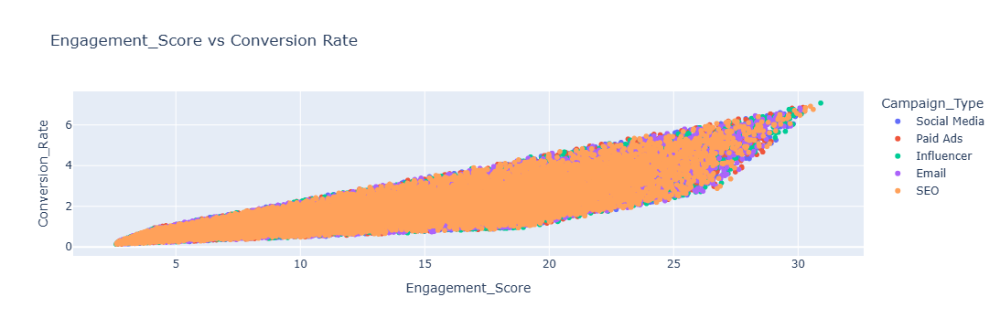

In [41]:
ctr_to_conversions = px.scatter(
    df, 
    x = 'Engagement_Score',
    y = 'Conversion_Rate',
    color = 'Campaign_Type',
    title = 'Engagement_Score vs Conversion Rate')

ctr_to_conversions.show()

Which campaigns achieve high ROI with relatively low spend?

In [42]:
roi_median = df['ROI'].median()
spend_median = df['Spend'].median()

high_roi_low_spend = df[(df['ROI'] > roi_median) & (df['Spend'] < spend_median)]

high_roi_low_spend[['Campaign_ID', 'Campaign_Type', 'Target_Audience','Spend',
                    'Revenue', 'ROI', 'Channel_Used', 'Conversion_Rate']].sort_values('ROI', ascending=False)

,Campaign_ID,Campaign_Type,Target_Audience,Spend,Revenue,ROI,Channel_Used,Conversion_Rate
12007,NY-CMP-13007,Paid Ads,Youth,60708.88,4579910,74.42,"Email, YouTube, Facebook",6.720746
21689,NY-CMP-22689,Influencer,Youth,56764.20,3821485,66.32,"Instagram, YouTube",5.463554
48715,NY-CMP-49715,Paid Ads,Premium Shoppers,56341.12,3717208,65.00,WhatsApp,5.215369
25356,NY-CMP-26356,Paid Ads,Premium Shoppers,51641.76,3363384,64.14,Facebook,5.242077
38329,NY-CMP-39329,Paid Ads,Youth,52267.52,3168256,59.64,"Google, Facebook, YouTube",5.609838
...,...,...,...,...,...,...,...,...
21838,NY-CMP-22838,Paid Ads,Youth,108360.00,243552,1.25,Google,0.991926
38981,NY-CMP-39981,Influencer,Working Women,140548.88,315736,1.25,"YouTube, Facebook, Email",2.930227
53592,NY-CMP-54592,Email,Youth,123032.52,276588,1.25,"Google, Email",1.790542
6084,NY-CMP-7084,Influencer,Premium Shoppers,86380.02,194256,1.25,"WhatsApp, Email, YouTube",0.602546


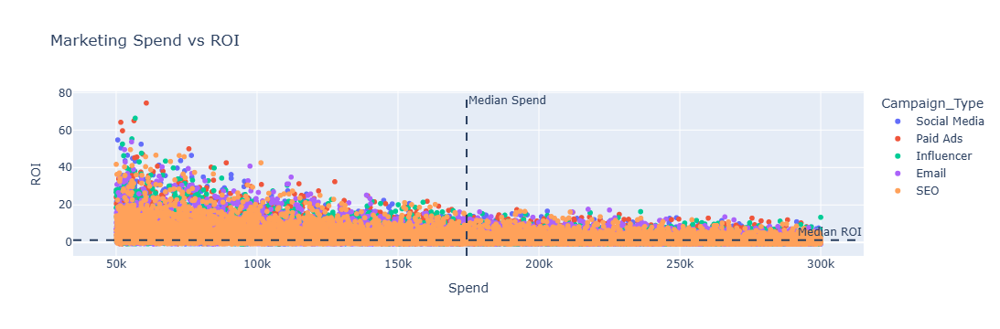

In [43]:
fig = px.scatter(
    df,
    x='Spend',
    y='ROI',
    color='Campaign_Type',
    hover_name='Campaign_ID',
    hover_data=['Revenue', 'Conversions', 'Conversion_Rate'],
    title='Marketing Spend vs ROI'
)

fig.add_vline(
    x=spend_median,
    line_dash='dash',
    annotation_text='Median Spend'
)

fig.add_hline(
    y=roi_median,
    line_dash='dash',
    annotation_text='Median ROI'
)

fig.show()